# GFMC, PQMC, and imaginary time: what our code actually runs

**GFMC uses imaginary-time evolution to project toward the ground state.** Imaginary time is the projection coordinate of the walker algorithm. It is not elapsed computer time or real-time quantum dynamics.

There are **two separate implementations** in this repository. The older Kagome GFMC notebook imports `gfmc.GFMC`. The recent rollback validation and energy checks call `kagome_qea.pqmc._project_once`. They share the same continuous-time projector principle and numerical helpers, but they are not the same class or interchangeable execution paths. My earlier explanation should have made this distinction explicit.

This notebook follows the **frozen source shared by the completed time-512, time-2048, and time-4096 campaigns**, displays its actual routines, and reproduces their saved energy comparisons, including the walker-count study and independent variational bound. Executing it reads local archives and makes plots; it does not launch a simulation.

In [1]:
from pathlib import Path
import ast
import hashlib
import inspect
import json
import sys

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import t as student_t
from IPython.display import Markdown, display

root = Path.cwd().resolve()
if not (root / 'code').is_dir():
    root = root.parent
assert (root / 'code/kagome_qea/pqmc.py').is_file(), 'Run from the repository or notebook/ directory.'
campaign_dir = root / 'data/kagome/validation/issue9-energy-20261026'
campaign = json.loads((campaign_dir / 'campaign.json').read_text())
source = campaign_dir / 'source'
for name, digest in campaign['source_sha256'].items():
    assert hashlib.sha256((source / name).read_bytes()).hexdigest() == digest, name
# Use a fresh kernel so imports resolve to the verified campaign source.
sys.path.insert(0, str(source / 'code'))
import kagome_qea.pqmc as pq
from kagome_qea.sample import make_sample
from gfmc.projector import GFMC
from qmc_numerics import weighted_interval, systematic
assert Path(pq.__file__).resolve() == (source / 'code/kagome_qea/pqmc.py').resolve(), 'Restart the kernel to use the frozen source.'
print('Base revision:', campaign['base_revision'])
print('Uncommitted solver patch SHA256:', campaign['solver_patch_sha256'])
print('Imported projector:', Path(pq.__file__).relative_to(root))
for name in ['code/kagome_qea/pqmc.py', 'code/gfmc/projector.py', 'code/qmc_numerics.py']:
    same = hashlib.sha256((root / name).read_bytes()).hexdigest() == campaign['source_sha256'][name]
    print(name, 'working source matches campaign:', same)

def show_code(function):
    display(Markdown('```python\n' + inspect.getsource(function) + '\n```'))

def show_nested(function, name):
    text = inspect.getsource(function)
    node = next(n for n in ast.walk(ast.parse(text))
                if isinstance(n, ast.FunctionDef) and n.name == name)
    display(Markdown('```python\n' + ast.get_source_segment(text, node) + '\n```'))

Base revision: 6f130ae809215bdcfc579239b0f6d2fdad540ac9
Uncommitted solver patch SHA256: 93d0501e69348867a532cb316bc5243d08e5be27bdb3c5d9c17492c8ee126c0b
Imported projector: data/kagome/validation/issue9-energy-20261026/source/code/kagome_qea/pqmc.py
code/kagome_qea/pqmc.py working source matches campaign: True
code/gfmc/projector.py working source matches campaign: True
code/qmc_numerics.py working source matches campaign: True


## 1. Names and execution paths

| Name | Meaning here | Exact code |
|---|---|---|
| Imaginary-time projection | Apply $e^{-\tau(H-E_T)}$ to suppress excited-state components | Represented by stochastic flips, weights, and resampling |
| GFMC | Green's function Monte Carlo: a walker realization of a projector | `code/gfmc/projector.py: GFMC.run` |
| PQMC | Projector quantum Monte Carlo; the name of our Kagome implementation | `code/kagome_qea/pqmc.py: _project_once` |
| Current energy study | Calls the Kagome projector directly, with two replicas and a flat guide | `data/kagome/validation/issue9-energy-20261026/energy_study.py: run_population` |

`GFMC.run` carries one configuration per walker and supports a guide. It resamples once per `tau_block`. The Kagome projector carries one or two replicas per walker, uses a flat guide, and can resample several times inside a block using `_branch_dt`. It also implements forward-walked overlap measurements. The two packages share `weighted_interval`, `systematic`, and `series_error`; neither projector imports the other.

The older `kagome_6x6_gfmc.ipynb` uses `from gfmc import GFMC`. Its filename is not a reliable description of its current settings: at the time this explanation was written, its code sets `L = 10`, while some prose still says `L = 8`. The current validation harness explicitly uses **L = 6**.

## 2. Hamiltonian, replicas, and walkers

For one replica, the actual operator is
$$H=-\sum_b J_b\sigma^z_{i_b}\sigma^z_{j_b}-h\sum_i\sigma_i^z-\Gamma\sum_i\sigma_i^x.$$
`make_sample(6, True, 0)` builds 108 spins and 216 stored bonds on a periodic Kagome lattice. It draws independent standard-normal couplings using PCG64 with entropy `[1000, 6, 0, 1]`. The study uses $h=0$, $\Gamma=0.05$, and coupling scale $\sigma=1$.

Each `_Walker` holds `spins`, `diagonal`, `weight`, `tag`, and `ancestor`. With `n_replicas=2`, `spins.shape == (2, 108)` and `diagonal` is the **sum of the two replica diagonal energies**. The pair Hamiltonian is $H^{(1)}+H^{(2)}$ without an inter-replica coupling. The replicas share a joint walker population and resampling history; they are not two independent error samples.

One population contains 5,000 joint walkers. The eight populations use separate RNG streams but the **same disorder sample**. Their scatter measures population variability, not uncertainty across disorder realizations.

In [2]:
sample = make_sample(6, True, 0)
ham = sample.hamiltonian(0.0)
N, R, gamma = ham.n_sites, 2, 0.05
rate = R * N * gamma
print('Sites per replica:', N, '| stored bonds:', len(sample.bonds))
print('Disorder entropy:', sample.seed_entropy.tolist())
print('Joint walker shape:', (R, N))
print('Total pair flip rate:', rate, '| mean proposed waiting time:', 1 / rate)
assert N == 108 and len(sample.bonds) == 216
show_code(pq._initial_walkers)

Sites per replica: 108 | stored bonds: 216
Disorder entropy: [1000, 6, 0, 1]
Joint walker shape: (2, 108)
Total pair flip rate: 10.8 | mean proposed waiting time: 0.09259259259259259


```python
def _initial_walkers(ham, n_walkers, n_replicas, rng):
    walkers = []
    for _ in range(n_walkers):
        bits = rng.integers(0, 2, size=(n_replicas, ham.n_sites))
        spins = np.where(bits == 0, np.int8(1), np.int8(-1))
        diagonal = 0.0
        for replica in range(n_replicas):
            diagonal += ham.diagonal_energy(spins[replica])
        walkers.append(_Walker(spins, diagonal))
    return walkers

```

## 3. Why this algorithm has imaginary time

In the ideal projection, expanding the initial state in energy eigenstates gives
$$e^{-\tau H}|\psi_{\rm init}\rangle = \sum_n c_n e^{-\tau E_n}|n\rangle.$$
Relative to the ground-state component, an excited component decays as $e^{-\tau(E_n-E_0)}$. This explains the purpose of increasing $\tau$. The code realizes the projection statistically with a finite walker population rather than constructing the exponential matrix. A finite population can still introduce bias or lose important regions of configuration space.

With a flat guiding function $\psi_g(s)=1$, the walker distribution represents amplitudes rather than $|\psi|^2$. The total flip rate for a joint walker is the constant
$$\lambda=RN\Gamma=2\times108\times0.05=10.8.$$
The local energy used during a hop-free segment is $E_L=D-\lambda$, where $D$ is the pair diagonal energy. `_advance` draws `rng.exponential(1.0 / rate)`. If the draw crosses the end of the requested interval, it truncates the waiting time and makes **no flip**. Otherwise it picks one of the $RN$ spins uniformly, updates the diagonal using `ham.flip_delta`, and flips that spin.

During each segment of duration $u$, `weighted_interval` returns
$$w_{\rm end}=w_0e^{-(E_L-E_T)u},\qquad I_w=\int_0^u w(t)\,dt,\qquad I_E=E_LI_w.$$
It evaluates the integrals using `expm1` and a small-exponent expansion. These are the actual weight and energy contributions; the estimator is not a simple average of endpoint energies.

In [3]:
show_code(pq._advance)
show_code(weighted_interval)

```python
def _advance(walker, ham, rate, shift, tau, rng):
    spins = walker.spins
    n_replicas, n_sites = spins.shape
    elapsed = 0.0
    energy_integral = 0.0
    time_integral = 0.0
    while elapsed < tau - 1e-15:
        # Mean waiting time of the constant-guide process is 1/λ.
        waiting = rng.exponential(1.0 / rate)
        hop = True
        if elapsed + waiting > tau:
            waiting = tau - elapsed
            hop = False
        local = walker.diagonal - rate
        walker.weight, energy_piece, time_piece = weighted_interval(
            walker.weight, local, shift, waiting
        )
        energy_integral += energy_piece
        time_integral += time_piece
        elapsed += waiting
        if hop:
            chosen = int(rng.integers(n_replicas * n_sites))
            replica, site = divmod(chosen, n_sites)
            walker.diagonal += ham.flip_delta(spins[replica], site)
            spins[replica, site] = -spins[replica, site]
    return energy_integral, time_integral

```

```python
def weighted_interval(weight, local_energy, shift, dt):
    """Integrate one hop-free interval of the Feynman–Kac weight.

    The weight grows as exp(alpha * t) with alpha = -(E_L - E_T). The time
    integral is weight * dt * (exp(alpha * dt) - 1) / (alpha * dt), evaluated
    with expm1 so a tiny alpha * dt does not cancel to zero. A large negative
    exponent may round the final weight to zero. A non-finite weight or a
    non-finite energy contribution is rejected.
    """
    alpha = -(local_energy - shift)
    exponent = alpha * dt
    if exponent > 700.0:
        raise RuntimeError("walker weight overflowed; reduce tau_block or the shift step")
    factor = math.exp(exponent)
    weight_end = weight * factor
    time_integral = weight * dt * _expm1_ratio(exponent)
    energy_integral = local_energy * time_integral
    if (
        not math.isfinite(weight_end)
        or not math.isfinite(time_integral)
        or not math.isfinite(energy_integral)
    ):
        raise RuntimeError("walker weight overflowed; reduce tau_block or the shift step")
    return weight_end, energy_integral, time_integral

```

## 4. Resampling, reference energy, and the block estimator

In `_project_once`, the initial `shift` is the mean pair local energy. For each population step of length `dt`, `population_step` advances every walker and applies **systematic resampling**. This chooses exactly the original number of children with probabilities proportional to the final weights; `_resample` copies configurations, tags, and ancestor IDs, and the new walkers have weight 1.

Let $W$ be the total weight before resampling and $M$ the walker count. The code computes
$$g=\frac{\log W-\log M}{dt},\qquad E_{\rm growth}=\frac{E_T-g}{R},\qquad E_T\leftarrow E_T-\frac{g}{2}.$$
`shift` is in **pair energy units**, while `growth_value` is divided by $R$ and is per replica. At finite walker count, population control can affect the estimate.

`one_block` repeatedly chooses $dt=\min(\mathrm{remaining},0.5/\mathrm{std}(D))$ through `_branch_dt`. If the spread is tiny or nonfinite, that helper returns the remaining interval. A block therefore contains adaptive resampling intervals; `tau_block=0.2` is an output block length, not a fixed spin-flip timestep.

For a completed block, the stored mixed energy is exactly
$$E_{\rm block}=\frac{\sum I_E}{R\sum I_w},$$
where the sums cover walkers and intervals inside that block. It is already the **total energy of one replica**. Divide by 108, not 216, for energy per spin. The stored block growth estimate is the arithmetic mean of the substep growth values; it is not explicitly weighted by the adaptive `dt`. Our drift comparison uses `energy_measure_trace`, the mixed block estimates.

In [4]:
show_code(pq._branch_dt)
show_code(pq._resample)
show_nested(pq._project_once, 'population_step')
show_nested(pq._project_once, 'one_block')
# The common helper exposes the exact systematic-resampling rule.
show_code(systematic)

```python
def _branch_dt(walkers, limit):
    """Longest resampling interval that keeps log-weights of order one.

    One block of length 0.2 multiplies weights by the diagonal-energy spread.
    On 216 bonds that spread is large enough to leave a single ancestor, and
    the forward-walked overlap then jumps from one Γ to the next.
    """
    limit = float(limit)
    if limit <= 0.0:
        raise ValueError("branch interval must be positive")
    diagonals = np.fromiter((walker.diagonal for walker in walkers), dtype=np.float64)
    spread = float(diagonals.std()) if diagonals.size else 0.0
    if not math.isfinite(spread) or spread < 1e-8:
        return limit
    return min(limit, 0.5 / spread)

```

```python
def _resample(walkers, rng):
    weights = np.fromiter((walker.weight for walker in walkers), dtype=np.float64)
    indexes, log_total = systematic(weights, rng)
    children = []
    for index in indexes:
        parent = walkers[int(index)]
        child = _Walker(parent.spins.copy(), parent.diagonal)
        child.tag = parent.tag
        child.ancestor = parent.ancestor
        children.append(child)
    return children, log_total

```

```python
def population_step(dt):
        nonlocal shift, walkers
        energy_sum = 0.0
        time_sum = 0.0
        for walker in walkers:
            energy_piece, time_piece = _advance(walker, ham, rate, shift, dt, rng)
            energy_sum += energy_piece
            time_sum += time_piece
        # Weight diversity before the resample. Descendant diversity is read
        # from the children, after the weights have been reset.
        weight_ess = _weight_ess(walkers)
        children, log_total = _resample(walkers, rng)
        log_growth = (log_total - math.log(n_walkers)) / dt
        # Growth estimates the pair. The shift used here is the one that
        # branched this step; the next step uses the damped update.
        growth_value = (shift - log_growth) / n_replicas
        shift = 0.5 * shift + 0.5 * (shift - log_growth)
        walkers = children
        return energy_sum, time_sum, growth_value, weight_ess
```

```python
def one_block(phase):
        nonlocal walkers, clock
        energy_sum = 0.0
        time_sum = 0.0
        growth_values = []
        covered = 0.0
        while covered < tau_block - 1e-12:
            dt = _branch_dt(walkers, tau_block - covered)
            energy_piece, time_piece, growth_value, _weight = population_step(dt)
            energy_sum += energy_piece
            time_sum += time_piece
            growth_values.append(growth_value)
            covered += dt
        clock += covered
        if time_sum <= 0.0:
            return
        value = energy_sum / time_sum / n_replicas
        if phase == "equilibration":
            equilibration_energy.append(value)
            equilibration_time.append(clock)
        elif phase == "measure":
            energies.append(value)
            growth.append(float(np.mean(growth_values)))
            measure_energy.append(value)
            measure_time.append(clock)
```

```python
def systematic(weights, rng):
    """Systematic resampling. Returns child indexes and log of the total weight.

    The total is a log-sum-exp over the positive mass, so two large finite
    weights do not add to infinity. A zero weight has no offspring. Negative,
    non-finite, and all-zero populations are rejected.
    """
    weights = np.asarray(weights, dtype=np.float64)
    if weights.ndim != 1 or weights.size < 1:
        raise RuntimeError("walker weights left the positive reals")
    if not np.isfinite(weights).all() or np.any(weights < 0.0):
        raise RuntimeError("walker weights left the positive reals")
    positive = np.flatnonzero(weights > 0.0)
    if positive.size == 0:
        raise RuntimeError("walker weights left the positive reals")
    logs = np.log(weights[positive])
    peak = float(logs.max())
    scaled = np.exp(logs - peak)
    alive = scaled > 0.0
    if not np.any(alive):
        raise RuntimeError("walker weights left the positive reals")
    positive = positive[alive]
    scaled = scaled[alive]
    sum_scaled = float(scaled.sum())
    if not math.isfinite(sum_scaled) or sum_scaled <= 0.0:
        raise RuntimeError("walker weights left the positive reals")
    log_total = peak + math.log(sum_scaled)
    cdf = np.cumsum(scaled)
    cdf /= cdf[-1]
    cdf[-1] = 1.0
    n_walkers = int(weights.size)
    positions = (rng.random() + np.arange(n_walkers)) / n_walkers
    picked = np.searchsorted(cdf, positions, side="left")
    picked = np.clip(picked, 0, positive.size - 1)
    return positive[picked], log_total

```

## 5. The different meanings of time

| Quantity | Code meaning | In the completed energy study |
|---|---|---|
| Imaginary time $\tau$ | Accumulated duration of the stochastic projection | 0 to 512 |
| `tau_block` | Duration covered by each output block | 0.2 |
| Adaptive `dt` | Interval between population resamplings | Chosen inside each block |
| Spin-flip waiting time | Exponential draw inside `_advance` | Mean $1/10.8$ for a joint walker |
| Equilibration time | `n_equilibrate` blocks, propagated but stored separately | 0 explicitly discarded blocks in this diagnostic study |
| Measurement duration | `n_measure` blocks, stored as a measurement trace | $2560\times0.2=512$ |
| `tau_forward` | Extra projection after tagging overlaps | Disabled by `n_forward_cycles=0` |
| Wall time | Seconds measured by `time.monotonic()` | Computational cost, not $\tau$ |

Units are $\hbar=1$: imaginary time has inverse-energy units, quoted in $1/\sigma$ with $\sigma=1$. It is not the inverse temperature of a finite-temperature trace calculation here.

`one_block` updates `clock += covered` and stores that clock at the **end** of each recorded block. Thus array index 0 represents a block ending near 0.2. Slicing `[1280:1920]` selects blocks covering time 256–384 (endpoints near 256.2 through 384).

Setting `n_equilibrate=0` records the initial transient too. The name `energy_measure_trace` does not establish equilibrium. We analyze late windows rather than taking the archive's whole-trajectory `energy` as the ground-state energy. With forward cycles enabled, that scalar `energy` also includes accepted forward substeps; it is distinct from the fixed measurement trace.

In [5]:
print(json.dumps(campaign['settings'], indent=2))
# Show the actual harness call, rather than silently substituting GFMC.run.
harness = (campaign_dir / 'energy_study.py').read_text()
assert hashlib.sha256(harness.encode()).hexdigest() == campaign['harness_sha256']
tree = ast.parse(harness)
call = next(n for n in ast.walk(tree) if isinstance(n, ast.Call)
            and isinstance(n.func, ast.Attribute) and n.func.attr == '_project_once')
display(Markdown('```python\n' + ast.get_source_segment(harness, call) + '\n```'))
print('RNGs: children 0–7 of SeedSequence(20261025).spawn(32).')
print('A passive harness wrapper saves partial traces; it returns the original _branch_dt result.')
print('Its smoke check reproduced all 21 solver result keys exactly.')

{
  "L": 6,
  "sample": 0,
  "pbc": true,
  "sigma": 1.0,
  "h": 0.0,
  "gamma": 0.05,
  "n_walkers": 5000,
  "n_replicas": 2,
  "tau_block": 0.2,
  "n_blocks": 2560,
  "populations": 8,
  "seed": 20261025,
  "spawned_children": 32,
  "n_forward_cycles": 0,
  "window_blocks": 320
}


```python
pq._project_once(make_sample(6, True, 0).hamiltonian(0.0), 0.05, rng,
            n_replicas=2, n_walkers=SETTINGS["n_walkers"], tau_block=0.2,
            n_equilibrate=0, n_measure=SETTINGS["n_blocks"], n_forward_cycles=0)
```

RNGs: children 0–7 of SeedSequence(20261025).spawn(32).
A passive harness wrapper saves partial traces; it returns the original _branch_dt result.
Its smoke check reproduced all 21 solver result keys exactly.


## 6. What the completed time-512 check found

For each population, first average its block energies over time 256–384 and over 384–512, then take the paired difference $d_p$. The study reports $\bar d$, $s_d/\sqrt{8}$, and $\bar d\pm t_{0.975,7}s_d/\sqrt{8}$. Correlated blocks and related walkers are not counted as independent samples. The following cells recompute this directly from the saved populations.

In [6]:
traces = []
for child in range(8):
    with np.load(campaign_dir / 'runs' / f'p{child}.npz', allow_pickle=False) as data:
        energy = data['energy_measure_trace'].copy()
        times = data['energy_measure_time'].copy()
        assert energy.shape == times.shape == (2560,)
        assert np.isfinite(energy).all()
        np.testing.assert_allclose(times, np.arange(1, 2561) * 0.2)
        assert int(data['n_replicas']) == R and int(data['n_sites']) == N
        traces.append(energy)
traces = np.stack(traces)
early = traces[:, 1280:1920].mean(axis=1)
late = traces[:, 1920:2560].mean(axis=1)
delta = late - early
se = delta.std(ddof=1) / np.sqrt(len(delta))
ci = delta.mean() + np.array([-1, 1]) * student_t.ppf(0.975, 7) * se
saved = json.loads((campaign_dir / 'final.json').read_text())
np.testing.assert_allclose(delta.mean(), saved['primary_late_shift']['mean'])
np.testing.assert_allclose(ci, saved['primary_late_shift']['ci95'])
print(f'Mean energy, time 256–384: {early.mean():.6f}')
print(f'Mean energy, time 384–512: {late.mean():.6f}')
print(f'Paired change: {delta.mean():.6f} ± {se:.6f} SE')
print(f'95% interval: [{ci[0]:.6f}, {ci[1]:.6f}]')
print(f'Change per spin: {delta.mean()/N:.8f}')
rows = ['| Population | Energy 256–384 | Energy 384–512 | Change |',
        '|---|---:|---:|---:|']
rows += [f'| {p} | {a:.6f} | {b:.6f} | {b-a:.6f} |'
         for p, (a, b) in enumerate(zip(early, late))]
display(Markdown('\n'.join(rows)))

Mean energy, time 256–384: -137.443950
Mean energy, time 384–512: -137.938079
Paired change: -0.494129 ± 0.170501 SE
95% interval: [-0.897299, -0.090959]
Change per spin: -0.00457527


| Population | Energy 256–384 | Energy 384–512 | Change |
|---|---:|---:|---:|
| 0 | -133.580095 | -133.582477 | -0.002382 |
| 1 | -137.989250 | -138.298318 | -0.309068 |
| 2 | -139.476397 | -140.459988 | -0.983591 |
| 3 | -135.426258 | -136.375841 | -0.949583 |
| 4 | -138.962214 | -138.980198 | -0.017984 |
| 5 | -137.567120 | -137.994923 | -0.427803 |
| 6 | -136.353921 | -137.549201 | -1.195281 |
| 7 | -140.196342 | -140.263682 | -0.067340 |

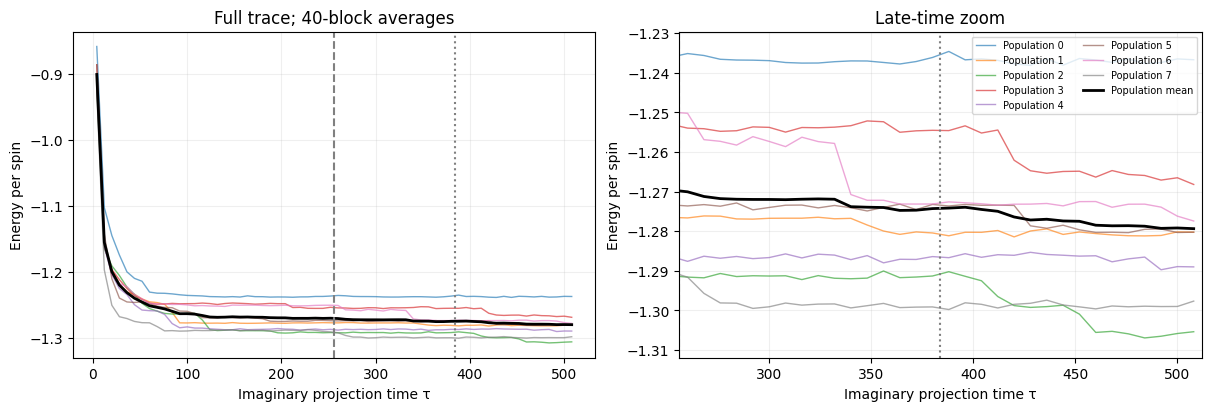

In [7]:
# The initial transient can hide late drift; show a late-time zoom as well.
width = 40
x = times.reshape(-1, width).mean(axis=1)
y = traces.reshape(8, -1, width).mean(axis=2)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax in axes:
    for child, row in enumerate(y):
        ax.plot(x, row/N, lw=1, alpha=0.65, label=f'Population {child}')
    ax.plot(x, y.mean(axis=0)/N, color='black', lw=2, label='Population mean')
    ax.axvline(256, color='gray', ls='--')
    ax.axvline(384, color='gray', ls=':')
    ax.set(xlabel='Imaginary projection time τ', ylabel='Energy per spin')
    ax.grid(alpha=0.2)
axes[0].set_title('Full trace; 40-block averages')
axes[1].set(xlim=(256, 512), title='Late-time zoom')
late_plot = y[:, x >= 256] / N
axes[1].set_ylim(late_plot.min()-0.005, late_plot.max()+0.005)
axes[1].legend(fontsize=7, ncol=2)
plt.show()

**The completed check resolves continuing energy drift.** The paired change is −0.494129 ± 0.170501 SE, with 95% interval [−0.897299, −0.090959]. All eight differences are negative. Their late-window energies also differ substantially, from about −133.58 to −140.46. Slow exploration, trapping, and finite-population effects remain possible explanations for the population disagreement.

A flat curve in one population is insufficient. Longer projection checks for continued drift; longer measurement after equilibration improves precision; increasing walker count tests a different source of error. The `energy_resolved` flag is a series-length/shape diagnostic, not a ground-state convergence certificate.

The follow-up through **time 2048 has completed**, with the same flat guide, walker count, disorder, and seed streams. Its predeclared primary comparison is time 1024–1536 versus 1536–2048. The earlier archives contain traces rather than restartable walker/RNG states, so it replayed from the original seeds. All eight energy and time prefixes through 512 match exactly. Results are reproduced below.

The extension protocol and implementation are in `data/kagome/validation/issue9-energy2048-20261026/PROTOCOL.md` and `extend_energy.py`. No energy-equivalence tolerance has been specified, so an interval containing zero would mean no drift was resolved at that precision, not proof of equality.

### Completed extension to time 2048

The primary paired change is now **−0.022578 ± 0.022260 SE**, with 95% interval **[−0.075215, 0.030058]**, or −0.00020906 per spin with interval [−0.00069643, 0.00027832]. This comparison does not resolve a late-time drift. It does not establish equivalence to a specified accuracy.

The population disagreement persists: late-window mean energies range from **−133.743151 to −142.204572**, a spread of about 8.46 total-energy units. Pairing cancels much of this persistent population offset, so the small uncertainty on the *change* is not a small uncertainty on the common ground-state energy. The mean late energy, −138.841037, is a diagnostic population average rather than a qualified ground-state estimate.

The trajectories are consistent with populations remaining in different regions. Establishing the cause requires further checks; the current data do not distinguish trapping from other finite-population effects. A longer projection has made the energies more stationary within populations but has not demonstrated agreement between populations. The next useful convergence check should address population size and exploration while retaining the flat guide. Susceptibility remains unqualified.

This extension was selected after seeing drift in the time-512 campaign. The intervals are descriptive and do not control errors across sequential extensions or multiple comparisons.

Verified all extension artifact hashes and all eight exact time-512 prefixes.
Energy 1024–1536: -138.818459
Energy 1536–2048: -138.841037
Paired change: -0.022578 ± 0.022260 SE
95% interval: [-0.075215, 0.030058]
Population range: -142.204572 to -133.743151


| Population | Energy 1024–1536 | Energy 1536–2048 | Change |
|---|---:|---:|---:|
| 0 | -133.762559 | -133.743151 | 0.019408 |
| 1 | -139.551472 | -139.547184 | 0.004288 |
| 2 | -142.187966 | -142.204572 | -0.016606 |
| 3 | -137.146891 | -137.152342 | -0.005452 |
| 4 | -139.327586 | -139.503445 | -0.175859 |
| 5 | -140.452432 | -140.455316 | -0.002884 |
| 6 | -137.822233 | -137.814368 | 0.007864 |
| 7 | -140.296534 | -140.307920 | -0.011386 |

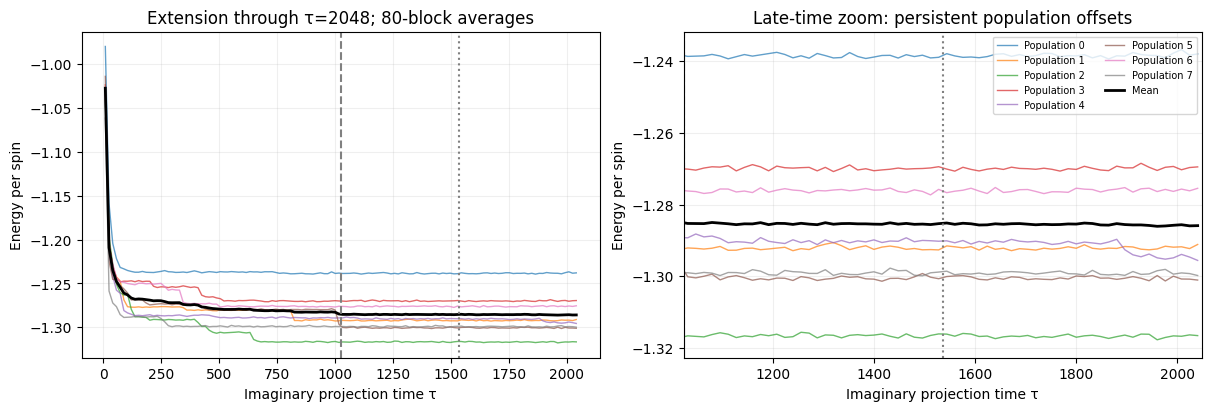

In [8]:
extended_dir = campaign_dir.parent / 'issue9-energy2048-20261026'
extended_campaign = json.loads((extended_dir / 'campaign.json').read_text())
assert extended_campaign['solver_patch_sha256'] == campaign['solver_patch_sha256']
manifest = json.loads((extended_dir / 'download_manifest.json').read_text())
for name, item in manifest.items():
    payload = (extended_dir / name).read_bytes()
    assert hashlib.sha256(payload).hexdigest() == item['sha256'], name
    assert len(payload) == item['bytes'], name
extended_traces = []
for child in range(8):
    with np.load(extended_dir / 'runs' / f'p{child}.npz', allow_pickle=False) as data:
        e = data['energy_measure_trace'].copy()
        extended_times = data['energy_measure_time'].copy()
        assert e.shape == extended_times.shape == (10240,) and np.isfinite(e).all()
        np.testing.assert_allclose(extended_times, np.arange(1, 10241) * 0.2)
        np.testing.assert_array_equal(e[:2560], traces[child])
        np.testing.assert_array_equal(extended_times[:2560], times)
        extended_traces.append(e)
extended_traces = np.stack(extended_traces)
extended_early = extended_traces[:, 5120:7680].mean(axis=1)
extended_late = extended_traces[:, 7680:10240].mean(axis=1)
extended_delta = extended_late - extended_early
extended_se = extended_delta.std(ddof=1) / np.sqrt(8)
extended_ci = extended_delta.mean() + np.array([-1, 1]) * student_t.ppf(0.975, 7) * extended_se
extended_saved = json.loads((extended_dir / 'final.json').read_text())
np.testing.assert_allclose(extended_ci, extended_saved['primary_late_shift']['ci95'])
print('Verified all extension artifact hashes and all eight exact time-512 prefixes.')
print(f'Energy 1024–1536: {extended_early.mean():.6f}')
print(f'Energy 1536–2048: {extended_late.mean():.6f}')
print(f'Paired change: {extended_delta.mean():.6f} ± {extended_se:.6f} SE')
print(f'95% interval: [{extended_ci[0]:.6f}, {extended_ci[1]:.6f}]')
print(f'Population range: {extended_late.min():.6f} to {extended_late.max():.6f}')
rows = ['| Population | Energy 1024–1536 | Energy 1536–2048 | Change |',
        '|---|---:|---:|---:|']
rows += [f'| {p} | {a:.6f} | {b:.6f} | {b-a:.6f} |'
         for p, (a, b) in enumerate(zip(extended_early, extended_late))]
display(Markdown('\n'.join(rows)))
width = 80
x_ext = extended_times.reshape(-1, width).mean(axis=1)
y_ext = extended_traces.reshape(8, -1, width).mean(axis=2) / N
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax in axes:
    for child, row in enumerate(y_ext):
        ax.plot(x_ext, row, lw=1, alpha=0.7, label=f'Population {child}')
    ax.plot(x_ext, y_ext.mean(axis=0), color='black', lw=2, label='Mean')
    ax.axvline(1024, color='gray', ls='--')
    ax.axvline(1536, color='gray', ls=':')
    ax.set(xlabel='Imaginary projection time τ', ylabel='Energy per spin')
    ax.grid(alpha=0.2)
axes[0].set_title('Extension through τ=2048; 80-block averages')
axes[1].set(xlim=(1024, 2048), title='Late-time zoom: persistent population offsets')
late_ext = y_ext[:, x_ext >= 1024]
axes[1].set_ylim(late_ext.min()-0.005, late_ext.max()+0.005)
axes[1].legend(fontsize=7, ncol=2)
plt.show()

## 7. Doubling to 20,480 blocks and increasing walker count

The next completed campaign doubled all eight 5,000-walker trajectories to **20,480 blocks, imaginary time 4096**. Since the saved files contain traces rather than restartable populations, it replayed the original seeds; all energy/time prefixes through 10,240 blocks reproduce exactly. Separate runs used 10,000 and 20,000 walkers through 2,560 blocks (time 512). These shorter runs compare walker counts at equal projection time; they cannot establish long-time behavior at the larger counts.

The flat guide, two replicas, disorder, Hamiltonian, and projector source are unchanged. The cell below verifies the downloaded artifacts and shows the actual campaign call. Local and remote smoke checks reproduced every solver result field with and without the passive trace observer, including a partial-write boundary. Matching child labels across walker counts does not imply matching RNG consumption.

All reported uncertainties use the eight independent populations on this single disorder sample. Intervals are descriptive 95% Student-t intervals with seven degrees of freedom, following sequential exploratory studies. A working stability target of 0.001 per spin (0.108 total) was declared for planning before these trajectories. It is not a user-specified accuracy requirement or a production pass.

In [9]:
blocks_dir = campaign_dir.parent / 'issue9-blocks-20261026'
blocks_campaign = json.loads((blocks_dir / 'campaign.json').read_text())
assert blocks_campaign['source_sha256'] == campaign['source_sha256']
assert blocks_campaign['solver_patch_sha256'] == campaign['solver_patch_sha256']
download = json.loads((blocks_dir / 'download_manifest.json').read_text())
remote_hashes = json.loads((blocks_dir / 'remote_sha256.json').read_text())
for name, item in download.items():
    payload = (blocks_dir / name).read_bytes()
    assert hashlib.sha256(payload).hexdigest() == item['sha256'] == remote_hashes[item['remote_path']], name
    assert len(payload) == item['bytes'], name
for name, digest in blocks_campaign['study_sha256'].items():
    assert hashlib.sha256((blocks_dir / name).read_bytes()).hexdigest() == digest, name
assert json.loads((blocks_dir / 'exit.json').read_text())['exit_code'] == 0
block_saved = json.loads((blocks_dir / 'final.json').read_text())
assert not block_saved['production_allowed'] and block_saved['recommended_equilibration_blocks'] is None
print(f'Verified {len(download)} downloaded files; unchanged frozen solver source.')
print(json.dumps(blocks_campaign['settings'], indent=2))
block_harness = (blocks_dir / 'walker_study.py').read_text()
block_call = next(n for n in ast.walk(ast.parse(block_harness)) if isinstance(n, ast.Call)
                  and isinstance(n.func, ast.Attribute) and n.func.attr == '_project_once')
display(Markdown('```python\n' + ast.get_source_segment(block_harness, block_call) + '\n```'))

def population_estimate(values, saved=None):
    values = np.asarray(values)
    mean = values.mean()
    se = values.std(ddof=1) / np.sqrt(8)
    ci = mean + np.array([-1, 1]) * student_t.ppf(0.975, 7) * se
    if saved is not None:
        np.testing.assert_allclose([mean, se], [saved['mean'], saved['se']])
        np.testing.assert_allclose(ci, saved['ci95'])
        np.testing.assert_allclose(values, saved['values'])
    return mean, se, ci

matrices = {}
for walkers in (5000, 10000, 20000):
    block_count = 20480 if walkers == 5000 else 2560
    rows = []
    for child in range(8):
        with np.load(blocks_dir / 'runs' / f'm{walkers}_p{child}.npz', allow_pickle=False) as data:
            e = data['energy_measure_trace'].copy()
            tm = data['energy_measure_time'].copy()
            assert e.shape == tm.shape == (block_count,) and np.isfinite(e).all()
            assert int(data['n_walkers']) == walkers and int(data['n_replicas']) == R
            np.testing.assert_allclose(tm, np.arange(1, block_count+1) * 0.2)
            if walkers == 5000:
                np.testing.assert_array_equal(e[:10240], extended_traces[child])
                np.testing.assert_array_equal(tm[:10240], extended_times)
            rows.append(e)
    matrices[walkers] = np.stack(rows)
print('Verified all 24 energy/time traces and eight exact 10,240-block prefixes.')

Verified 113 downloaded files; unchanged frozen solver source.
{
  "L": 6,
  "sample_id": 0,
  "gamma": 0.05,
  "sigma": 1.0,
  "n_replicas": 2,
  "tau_block": 0.2,
  "n_blocks": 2560,
  "populations": 8,
  "walker_counts": [
    10000,
    20000
  ],
  "long_blocks": 20480,
  "long_walkers": 5000,
  "seed": 20261025,
  "spawned_children": 32,
  "n_equilibrate": 0,
  "n_forward_cycles": 0,
  "workers": 16,
  "working_energy_tolerance_per_spin": 0.001
}


```python
pq._project_once(make_sample(6, True, 0).hamiltonian(0.0), 0.05, rng,
                               n_walkers=walkers, n_replicas=2, tau_block=0.2,
                               n_equilibrate=0, n_measure=blocks, n_forward_cycles=0)
```

Verified all 24 energy/time traces and eight exact 10,240-block prefixes.


### An independent reference makes the plateau test stronger

An Ising MILP found a configuration with classical energy −143.534342179 and a matching dual bound to solver precision. This is an independent calculation, described in `classical_bound.py`; it neither guides nor changes the QMC paths. Binary variables use $s_i=1-2x_i$, $y_{ij}=x_i\mathbin{\mathrm{XOR}}x_j$, and energy $-\sum J+2\sum Jy$.

For a normalized product state with $\langle Z_i\rangle=s_i\cos\theta_i$ and $\langle X_i\rangle=\sin\theta_i$, its quantum energy is
$$E_{\rm var}=-\sum_bJ_b s_{i_b}s_{j_b}\cos\theta_{i_b}\cos\theta_{j_b}-\Gamma\sum_i\sin\theta_i.$$
Evaluating the saved optimized angles gives **$E_0\leq -143.636557202$**, or −1.329968122 per spin. MILP optimality and product-state optimality are unnecessary for this upper-bound inequality: any normalized trial state suffices. The classical dual bound minus $N\Gamma$ also gives $E_0\geq-148.934342179$, subject to solver precision.

The dashed reference in the plots is an **upper bound**, not the exact quantum ground-state energy. A plateau significantly above it fails the accuracy check; reaching or crossing it would only pass this one check. The following cell directly evaluates the saved state without rerunning either optimization.

Classical reference: -143.534342179; quantum variational upper bound: -143.636557202
Energy at time 3072–4096: -139.092153 ± 0.860096 SE; 95% interval [-141.12595733 -137.05834948]
Change from time 2048–3072: -0.128846 ± 0.074120 SE; interval [-0.30411188  0.04642045]
Change from previous final window: -0.251116 ± 0.123222 SE; interval [-0.54248974  0.04025754]
Mean above variational upper bound by 4.544404; lowest population above it by 1.446135.
Drift interval within working ±0.108 total-energy tolerance: False


| Population | Energy 2048–3072 | Energy 3072–4096 | Change | Above upper bound |
|---|---:|---:|---:|---:|
| 0 | -134.013860 | -134.592748 | -0.578888 | 9.043809 |
| 1 | -139.530870 | -139.551609 | -0.020739 | 4.084948 |
| 2 | -142.184440 | -142.190422 | -0.005982 | 1.446135 |
| 3 | -137.160582 | -137.158838 | 0.001744 | 6.477719 |
| 4 | -139.845864 | -139.834898 | 0.010965 | 3.801659 |
| 5 | -140.870498 | -141.166845 | -0.296348 | 2.469712 |
| 6 | -137.813099 | -137.942703 | -0.129604 | 5.693855 |
| 7 | -140.287250 | -140.299164 | -0.011914 | 3.337393 |

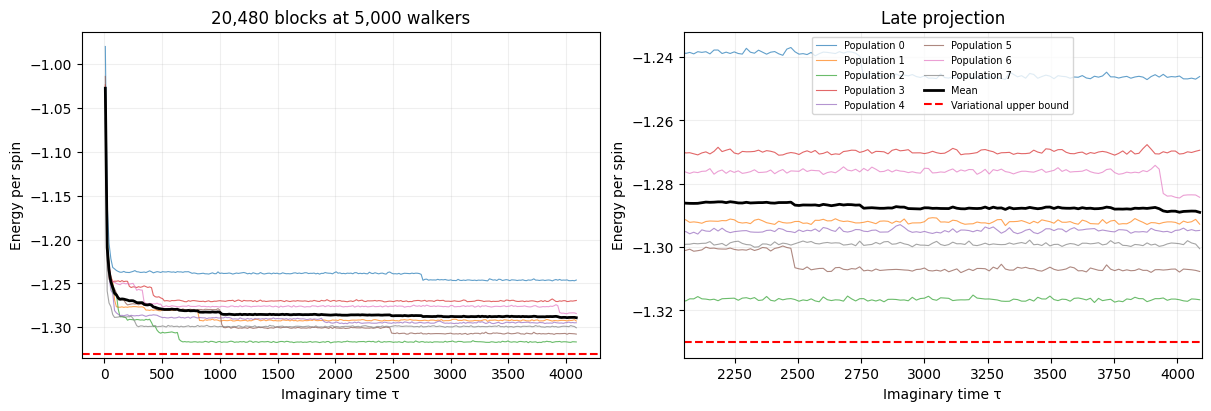

In [10]:
bound = json.loads((blocks_dir / 'bound_sample0.json').read_text())
assert bound == block_saved['independent_bound']
bound_spins = np.asarray(bound['spins'])
angles = np.asarray(bound['product_angles'])
z = bound_spins * np.cos(angles)
x_product = np.sin(angles)
np.testing.assert_allclose(z*z+x_product*x_product, 1, atol=1e-14)
classical = -np.dot(ham.J, bound_spins[ham.bonds[:, 0]]*bound_spins[ham.bonds[:, 1]])
upper = -np.dot(ham.J, z[ham.bonds[:, 0]]*z[ham.bonds[:, 1]]) - gamma*x_product.sum()
np.testing.assert_allclose(classical, bound['classical_energy'])
np.testing.assert_allclose(upper, bound['quantum_variational_upper_bound'], rtol=0, atol=1e-10)
print(f'Classical reference: {classical:.9f}; quantum variational upper bound: {upper:.9f}')
long_traces = matrices[5000]
long_early = long_traces[:, 10240:15360].mean(axis=1)
long_late = long_traces[:, 15360:20480].mean(axis=1)
long_summary = block_saved['long_block_summary']
long_mean, long_se, long_ci = population_estimate(long_late, long_summary['late_energy'])
drift_mean, drift_se, drift_ci = population_estimate(long_late-long_early, long_summary['primary_late_drift'])
change_mean, change_se, change_ci = population_estimate(long_late-extended_late, long_summary['change_from_previous_late'])
print(f'Energy at time 3072–4096: {long_mean:.6f} ± {long_se:.6f} SE; 95% interval {long_ci}')
print(f'Change from time 2048–3072: {drift_mean:.6f} ± {drift_se:.6f} SE; interval {drift_ci}')
print(f'Change from previous final window: {change_mean:.6f} ± {change_se:.6f} SE; interval {change_ci}')
print(f'Mean above variational upper bound by {long_mean-upper:.6f}; lowest population above it by {long_late.min()-upper:.6f}.')
print('Drift interval within working ±0.108 total-energy tolerance:', np.max(np.abs(drift_ci)) <= 0.108)
rows = ['| Population | Energy 2048–3072 | Energy 3072–4096 | Change | Above upper bound |',
        '|---|---:|---:|---:|---:|']
rows += [f'| {p} | {a:.6f} | {b:.6f} | {b-a:.6f} | {b-upper:.6f} |'
         for p, (a, b) in enumerate(zip(long_early, long_late))]
display(Markdown('\n'.join(rows)))
long_times = np.arange(1, 20481) * 0.2
x_long = long_times.reshape(-1, 80).mean(axis=1)
y_long = long_traces.reshape(8, -1, 80).mean(axis=2) / N
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax in axes:
    for child, row in enumerate(y_long):
        ax.plot(x_long, row, lw=0.8, alpha=0.7, label=f'Population {child}')
    ax.plot(x_long, y_long.mean(axis=0), color='black', lw=2, label='Mean')
    ax.axhline(upper/N, color='red', ls='--', label='Variational upper bound')
    ax.set(xlabel='Imaginary time τ', ylabel='Energy per spin')
    ax.grid(alpha=0.2)
axes[0].set_title('20,480 blocks at 5,000 walkers')
axes[1].set(xlim=(2048, 4096), title='Late projection')
axes[1].set_ylim(upper/N-0.005, y_long[:, x_long>=2048].max()+0.005)
axes[1].legend(fontsize=7, ncol=2)
plt.show()

| Walkers | Energy, time 384–512 | SE | Late drift |
|---|---:|---:|---:|
| 5,000 | -137.938079 | 0.785477 | -0.494129 |
| 10,000 | -137.252572 | 0.864599 | -0.450844 |
| 20,000 | -137.428585 | 0.625156 | -0.060405 |

| Walker contrast | Energy change | 95% interval | Within ±0.108? |
|---|---:|---|---|
| 10,000 minus 5,000 | 0.685506 | [-1.255206, 2.626219] | False |
| 20,000 minus 10,000 | -0.176013 | [-2.292754, 1.940729] | False |
| 20,000 minus 5,000 | 0.509494 | [-1.743835, 2.762823] | False |

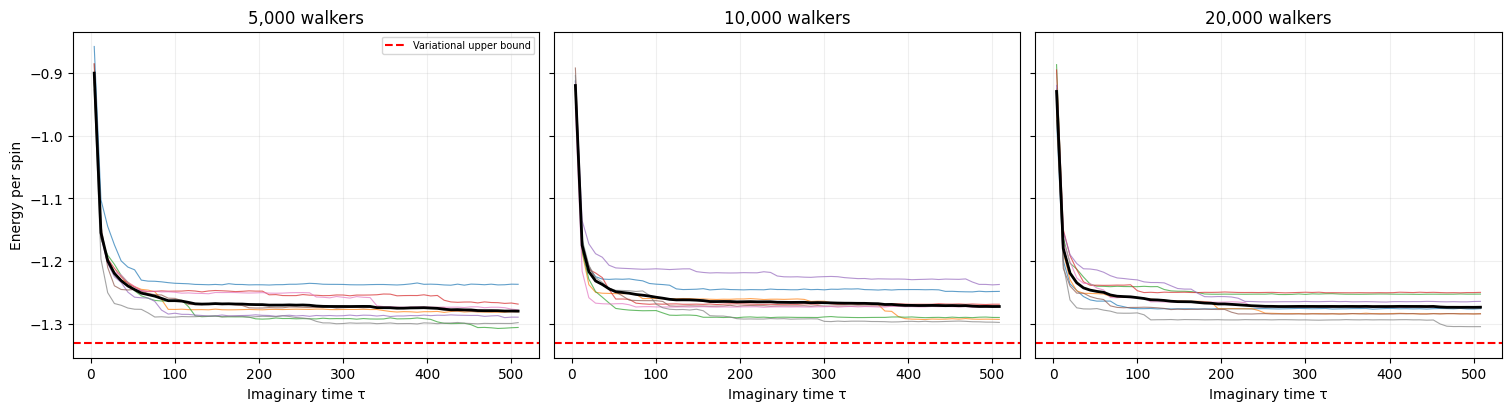

In [11]:
short_late = {}
rows = ['| Walkers | Energy, time 384–512 | SE | Late drift |', '|---|---:|---:|---:|']
for walkers, matrix in matrices.items():
    short = matrix[:, :2560]
    short_late[walkers] = short[:, 1920:].mean(axis=1)
    summary = block_saved['walker_summaries'][str(walkers)]
    mean, se, ci = population_estimate(short_late[walkers], summary['late_energy'])
    dm, ds, dc = population_estimate(short_late[walkers]-short[:, 1280:1920].mean(axis=1), summary['late_drift'])
    rows.append(f'| {walkers:,} | {mean:.6f} | {se:.6f} | {dm:.6f} |')
display(Markdown('\n'.join(rows)))
rows = ['| Walker contrast | Energy change | 95% interval | Within ±0.108? |', '|---|---:|---|---|']
for smaller, larger in ((5000, 10000), (10000, 20000), (5000, 20000)):
    saved_contrast = block_saved['walker_contrasts'][f'{larger}_minus_{smaller}']
    mean, se, ci = population_estimate(short_late[larger]-short_late[smaller], saved_contrast)
    rows.append(f'| {larger:,} minus {smaller:,} | {mean:.6f} | [{ci[0]:.6f}, {ci[1]:.6f}] | {np.max(np.abs(ci)) <= 0.108} |')
display(Markdown('\n'.join(rows)))
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True, constrained_layout=True)
x_short = (np.arange(1, 2561)*0.2).reshape(-1, 40).mean(axis=1)
for ax, (walkers, matrix) in zip(axes, matrices.items()):
    y_short = matrix[:, :2560].reshape(8, -1, 40).mean(axis=2) / N
    for row in y_short:
        ax.plot(x_short, row, lw=0.8, alpha=0.7)
    ax.plot(x_short, y_short.mean(axis=0), color='black', lw=2)
    ax.axhline(upper/N, color='red', ls='--', label='Variational upper bound')
    ax.set(title=f'{walkers:,} walkers', xlabel='Imaginary time τ')
    ax.grid(alpha=0.2)
axes[0].set_ylabel('Energy per spin')
axes[0].legend(fontsize=7)
plt.show()

**Doubling the blocks helps some populations but does not establish convergence.** The latest mean is −139.092153 ± 0.860096 SE, and the population range is −142.190422 to −134.592748. The mean decrease relative to the preceding campaign's final window is −0.251116 ± 0.123222 SE, with interval [−0.542490, 0.040258]. Occasional downward jumps separated by long plateaus are consistent with slow exploration; these energy traces alone do not identify its cause.

The primary late-window change, −0.128846 ± 0.074120 SE, has interval [−0.304112, 0.046420]. Although that interval includes zero, it extends outside the working ±0.108 tolerance. More decisively, the mean remains **4.544404 above the variational upper bound**, and even the lowest population is about **1.446135 above it**. Small fluctuations on these plateaus do not imply an accurate ground-state energy.

At matched time 384–512, increasing walkers from 5,000 to 10,000 to 20,000 gives mean energies −137.938079, −137.252572, and −137.428585. Their contrast intervals are broad and none fits within ±0.108. The data show no clear systematic improvement at that time; they cannot determine whether larger populations would improve after longer projection.

**No production equilibration block count is qualified.** The stronger-field screen below tests whether convergence improves when the transverse field increases, retaining the flat guide. Selecting only the lowest-energy run would bias the estimate. Fresh-seed and representative disorder/field checks are needed after choosing candidate settings, and susceptibility needs the separate forward-time validation below.

## 8. Stronger transverse fields on the same 6×6 sample

The weak-field studies used $\Gamma=0.05$ and $\sigma=1$. Following the suggestion to investigate the paramagnetic regime, the next screen uses **$\Gamma/\sigma=3$ and $5$**, with the same disorder sample and the same flat-guide projector. These are candidate paramagnetic controls; the field values alone do not establish the phase.

For each field, eight independent populations at each of 5,000 and 10,000 walkers run 64 blocks of duration 0.2, reaching $\tau=12.8$. All initial transients remain in the archive and no forward cycles run. The late comparison is $\tau=6.4$–9.6 versus 9.6–12.8. Disjoint children of `SeedSequence(20261026).spawn(32)` supply the populations. The walker contrast uses an independent-sample Welch interval.

The code below verifies the downloaded artifacts, displays the exact frozen harness call, and recomputes population statistics from the saved traces. It does not launch simulations. The all-X product state gives the field-specific upper bound $E_0\leq -108\Gamma$; the saved low-field product state is also reevaluated at each new field. The second-order high-field expression $-108\Gamma-\sum_b J_b^2/(4\Gamma)$ is an approximation, not a bound.


```python
def project(gamma, walkers, child, blocks, uncoupled=False):
    ham = make_sample(6, True, 0).hamiltonian(0.0)
    if uncoupled:
        ham = ham.with_classical_scale(0.0)
    rng = np.random.default_rng(np.random.SeedSequence(SETTINGS["seed"]).spawn(32)[child])
    return pqmc._project_once(ham, gamma, rng, n_walkers=walkers, n_replicas=2,
                              tau_block=0.2, n_equilibrate=0, n_measure=blocks,
                              n_forward_cycles=0)
```

| Gamma/sigma | Walkers | Late energy | SE | Late drift | Drift 95% interval |
|---|---:|---:|---:|---:|---|
| 3 | 5,000 | -344.747539 | 0.080377 | -0.151429 | [-0.484147, 0.181288] |
| 3 | 10,000 | -344.733091 | 0.038299 | -0.079096 | [-0.283923, 0.125730] |
| 5 | 5,000 | -552.476478 | 0.019745 | -0.024075 | [-0.114111, 0.065961] |
| 5 | 10,000 | -552.482694 | 0.011308 | -0.023680 | [-0.053251, 0.005891] |

| Gamma/sigma | 10,000 minus 5,000 | Welch 95% interval | Within ±0.108? |
|---|---:|---|---|
| 3 | 0.014448 | [-0.183874, 0.212769] | False |
| 5 | -0.006217 | [-0.056217, 0.043784] | True |

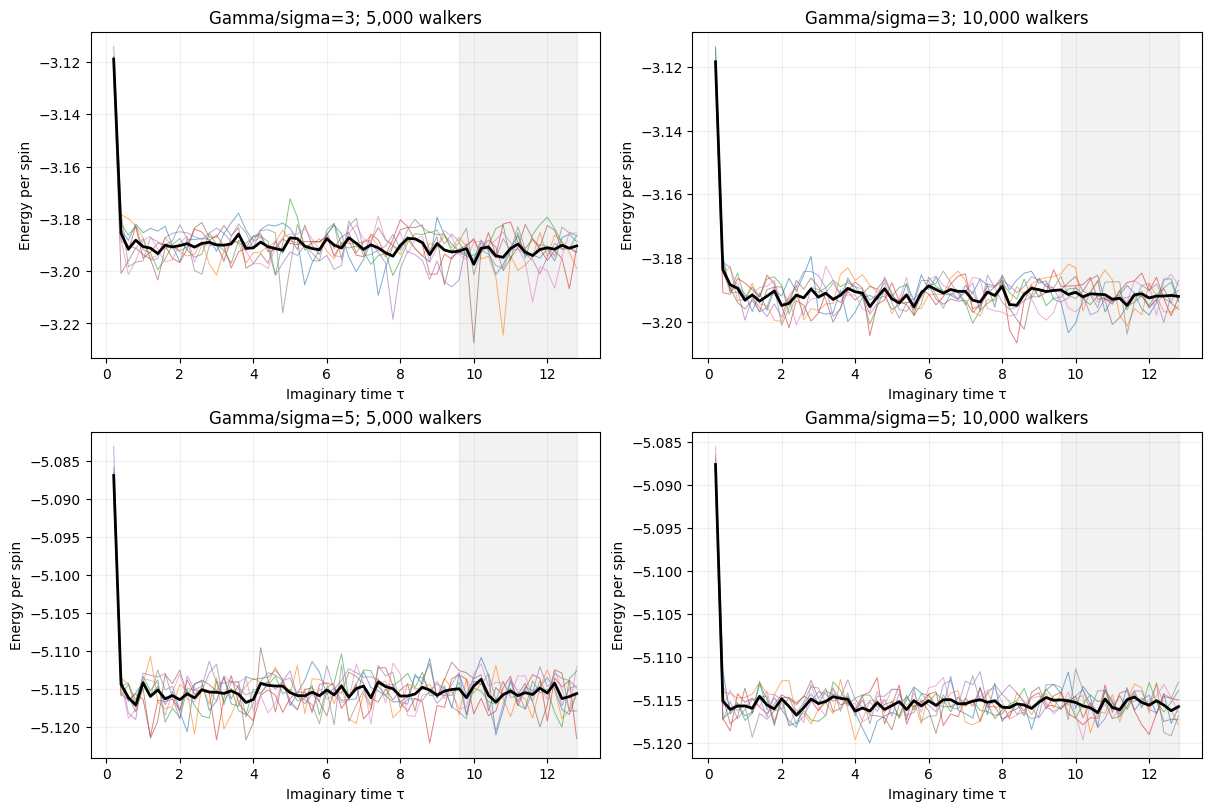

In [12]:
high_dir = campaign_dir.parent / 'issue9-highfield-20261026'
high_campaign = json.loads((high_dir / 'campaign.json').read_text())
assert high_campaign['source_sha256'] == campaign['source_sha256']
assert high_campaign['solver_patch_sha256'] == campaign['solver_patch_sha256']
for name, digest in high_campaign['study_sha256'].items():
    assert hashlib.sha256((high_dir/name).read_bytes()).hexdigest() == digest
high_manifest = json.loads((high_dir/'download_manifest.json').read_text())
for name, entry in high_manifest.items():
    content = (high_dir/name).read_bytes()
    assert len(content) == entry['bytes']
    assert hashlib.sha256(content).hexdigest() == entry['sha256']
high_saved = json.loads((high_dir/'final.json').read_text())
assert high_saved['settings'] == high_campaign['settings']
assert not high_saved['production_allowed'] and not high_saved['phase_established']
high_harness = (high_dir/'field_study.py').read_text()
project_node = next(node for node in ast.parse(high_harness).body
                    if isinstance(node, ast.FunctionDef) and node.name == 'project')
display(Markdown('```python\n'+ast.get_source_segment(high_harness, project_node)+'\n```'))
high_matrices = {}
rows = ['| Gamma/sigma | Walkers | Late energy | SE | Late drift | Drift 95% interval |',
        '|---|---:|---:|---:|---:|---|']
for field_index, field in enumerate((3.0, 5.0)):
    for walker_index, walkers in enumerate((5000, 10000)):
        traces_high = []
        for child in range(8*(2*field_index+walker_index), 8*(2*field_index+walker_index+1)):
            with np.load(high_dir/'runs'/f'g{field:g}_m{walkers}_p{child}.npz', allow_pickle=False) as archive:
                np.testing.assert_allclose(archive['energy_measure_time'], np.arange(1,65)*0.2)
                traces_high.append(archive['energy_measure_trace'].copy())
        matrix = np.stack(traces_high)
        high_matrices[field, walkers] = matrix
        row = high_saved['summaries'][f'g{field:g}_m{walkers}']
        mean, se, ci = population_estimate(matrix[:,48:].mean(axis=1), row['late_energy'])
        dm, ds, dc = population_estimate(matrix[:,48:].mean(axis=1)-matrix[:,32:48].mean(axis=1), row['late_drift'])
        rows.append(f'| {field:g} | {walkers:,} | {mean:.6f} | {se:.6f} | {dm:.6f} | [{dc[0]:.6f}, {dc[1]:.6f}] |')
display(Markdown('\n'.join(rows)))
rows = ['| Gamma/sigma | 10,000 minus 5,000 | Welch 95% interval | Within ±0.108? |', '|---|---:|---|---|']
for field in (3.0, 5.0):
    a, b = [high_matrices[field, walkers][:,48:].mean(axis=1) for walkers in (5000,10000)]
    variance = np.array([a.var(ddof=1), b.var(ddof=1)])/8
    df = variance.sum()**2 / np.sum(variance**2/7)
    mean = b.mean()-a.mean()
    ci = mean + np.array([-1,1])*student_t.ppf(.975, df)*np.sqrt(variance.sum())
    np.testing.assert_allclose(ci, high_saved['walker_contrasts'][str(field)]['ci95'])
    rows.append(f'| {field:g} | {mean:.6f} | [{ci[0]:.6f}, {ci[1]:.6f}] | {max(abs(ci)) <= .108} |')
display(Markdown('\n'.join(rows)))
fig, axes = plt.subplots(2,2,figsize=(12,8),constrained_layout=True)
for i, field in enumerate((3.0,5.0)):
    for j, walkers in enumerate((5000,10000)):
        ax = axes[i,j]
        matrix = high_matrices[field,walkers]/N
        for trace in matrix:
            ax.plot(np.arange(1,65)*.2, trace, lw=.7, alpha=.6)
        ax.plot(np.arange(1,65)*.2, matrix.mean(axis=0), color='black', lw=2)
        ax.axvspan(9.6,12.8,color='gray',alpha=.1)
        ax.set(title=f'Gamma/sigma={field:g}; {walkers:,} walkers', xlabel='Imaginary time τ', ylabel='Energy per spin')
        ax.grid(alpha=.2)
plt.show()


**Completed stronger-field screen.** The table uses total energies per replica.

At Gamma/sigma=3, the 10,000-walker late energy is -344.733091 ± 0.038299 SE. Its drift interval is [-0.283923, 0.125730]; the walker-contrast interval is [-0.183874, 0.212769].

At Gamma/sigma=5, the 10,000-walker late energy is -552.482694 ± 0.011308 SE. Its drift interval is [-0.053251, 0.005891]; the walker-contrast interval is [-0.056217, 0.043784].

These comparisons use the working ±0.108 total-energy tolerance. Gamma/sigma=5 with 10,000 walkers meets both the tested drift and walker-count criteria; there is no demonstrated energy failure at this accuracy. Energy production is justified at this tested L6/sample0/field setting with 32 equilibration blocks and at least 32 measurement blocks of duration 0.2 and eight independent populations. With no forward cycles, this partition preserves the tested dynamics while excluding the initial transient from the energy estimator. Longer projection and larger-population checks would add confidence. The archived production_allowed=false records the original screen protocol, rather than a failed Gamma=5 energy criterion. These energy-only runs contain no q2 or susceptibility measurements, so pure overlap and correlations require the separate forward-time validation below. Energy stability does not establish a paramagnetic phase. The earlier weak-field convergence failure remains unresolved.

## 9. Why susceptibility needs a separate check

The code uses $q=N^{-1}\sum_i s_i^{(1)}s_i^{(2)}$ and $\chi_{\rm SG}=N\langle q^2\rangle$. A raw histogram from a flat-guide population samples amplitudes, so simply averaging the instantaneous $q^2$ is not the desired pure ground-state expectation.

When forward cycles are enabled, `_project_once` tags each walker with its current overlap and a unique ancestor ID. Children inherit the tag. After additional projection, the code averages powers of the inherited tags over the surviving descendants. **This forward-projection duration is `tau_forward`; it is distinct from the cumulative projection time on our energy plot.**

The default cycle stops before descendant Kish size falls below 8 or unique ancestors fall below 2 (with a smaller-population rule below 16 walkers). A rejected step restores a deep copy of the prior physical population and the prior shift. Its RNG draws remain consumed, and rejected time and energy are excluded. The attained forward time can therefore be shorter than requested, and truncated cycles do not receive resolved overlap flags.

The energy-only study sets `n_forward_cycles=0`, so none of these tagging cycles execute. Extending its energy trajectory does not by itself extend or validate the susceptibility estimator.

## Practical reading guide

- **Algorithm:** continuous-time stochastic ground-state projection, with a flat guide.
- **Current implementation:** `kagome_qea.pqmc._project_once`, not the separate `GFMC.run` class.
- **Horizontal axis:** accumulated imaginary projection time, measured in inverse-energy units.
- **Energy:** weight-and-time mixed block estimate, divided by replica count.
- **Current evidence:** the weak-field run through time 4096 leaves population offsets above a valid variational upper bound. At Gamma/sigma=5, energy meets the tested stability criteria. The next section measures pure-overlap forward-time dependence and sampling precision for susceptibility and the finite-size q EA proxy.

Source references: `code/kagome_qea/pqmc.py`, `code/gfmc/projector.py`, `code/qmc_numerics.py`, `code/ising/hamiltonian.py`, and `code/kagome_qea/sample.py`. The displayed routines above come from the verified frozen campaign source.

## 10. Susceptibility and Edwards–Anderson overlap at Gamma/sigma=5

Final production retains the pure moments for every disorder sample $J$:
$$m_{2,J}=\langle q^2\rangle_J,\qquad
\chi_{\mathrm{SG},J}=N m_{2,J},\qquad
q_{\mathrm{EA}}^2=[m_{2,J}],\qquad q_{\mathrm{EA}}=\sqrt{[m_{2,J}]}.$$
The square root is taken **after** averaging over disorder. This follows the convention in `kagome_qea_scan.ipynb`. At finite size it is an RMS overlap proxy: uncoupled spins have $\chi_{\mathrm{SG}}=1$ and $q_{\mathrm{EA}}=1/\sqrt{N}$, so a positive value alone does not establish thermodynamic spin-glass order. Here $N=108$ and the comparison uses one disorder sample; its intervals describe projector sampling uncertainty.

The unchanged flat-guide solver uses 10,000 walkers, 32 equilibration and 32 measurement blocks of duration 0.2, followed by eight tagging/forward cycles. Eight independent populations run at each requested forward time 0.1, 0.2, 0.4 and 0.8. Seeds are disjoint children of `SeedSequence(2026102603).spawn(32)`. The uncertainty unit is the mean of the eight cycles within one population. Adjacent-duration comparisons use independent-population Welch intervals. Every cycle is retained, including any cycle stopped by the ancestry floor.

The following cells verify file hashes, display the actual harness and recompute the results from all 32 archives. They launch no simulations. The energy comparison uses only `energy_measure_trace`; the scalar `energy` also includes accepted forward steps.


```python
def project(duration, child, walkers=10000, blocks=32, cycles=8):
    ham = make_sample(6, True, 0).hamiltonian(0.0)
    rng = np.random.default_rng(np.random.SeedSequence(SETTINGS['seed']).spawn(32)[child])
    return pqmc._project_once(ham, 5.0, rng, n_walkers=walkers, n_replicas=2,
                              tau_block=0.2, n_equilibrate=blocks, n_measure=blocks,
                              tau_forward=duration, n_forward_cycles=cycles)
```

| Forward time | chi SG ± SE | chi SG 95% CI | q EA (RMS) | q EA 95% CI | Truncated / 64 | Min descendant Kish |
|---:|---:|---|---:|---|---:|---:|
| 0.1 | 1.046178 ± 0.006875 | [1.029922, 1.062434] | 0.098422 | [0.097654, 0.099183] | 0 | 887.2 |
| 0.2 | 1.081062 ± 0.024506 | [1.023115, 1.139009] | 0.100049 | [0.097331, 0.102696] | 0 | 62.4 |
| 0.4 | 1.052394 ± 0.013094 | [1.021431, 1.083357] | 0.098714 | [0.097251, 0.100155] | 0 | 55.7 |
| 0.8 | 1.020229 ± 0.023033 | [0.965765, 1.074693] | 0.097193 | [0.094564, 0.099754] | 0 | 20.8 |

| Forward comparison | chi SG difference | Welch 95% CI |
|---|---:|---|
| 0.2_minus_0.1 | 0.034884 | [-0.023688, 0.093456] |
| 0.4_minus_0.2 | -0.028668 | [-0.090034, 0.032699] |
| 0.8_minus_0.4 | -0.032165 | [-0.090418, 0.026087] |

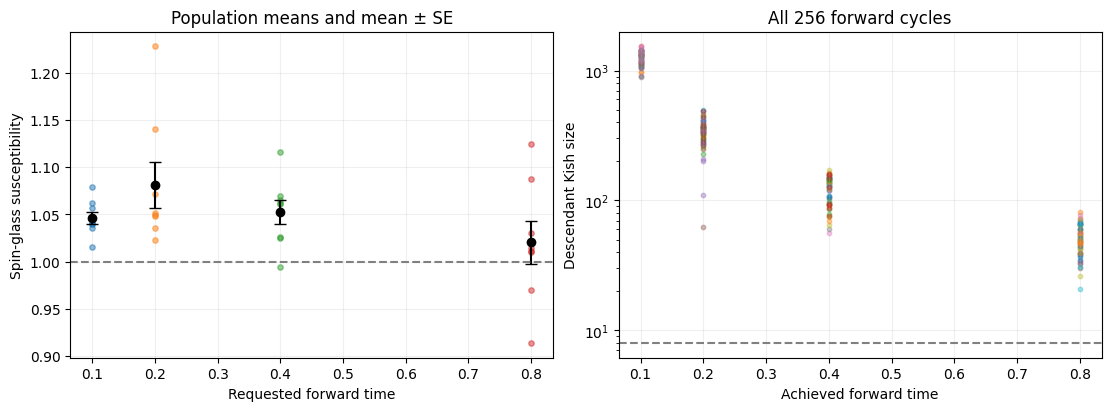

In [13]:
overlap_dir = campaign_dir.parent/'issue9-overlap-highfield-20261026'
overlap_campaign = json.loads((overlap_dir/'campaign.json').read_text())
assert overlap_campaign['source_sha256'] == campaign['source_sha256']
for name, digest in overlap_campaign['study_sha256'].items():
    assert hashlib.sha256((overlap_dir/name).read_bytes()).hexdigest() == digest
overlap_manifest = json.loads((overlap_dir/'download_manifest.json').read_text())
for name, entry in overlap_manifest.items():
    content = (overlap_dir/name).read_bytes()
    assert len(content) == entry['bytes']
    assert hashlib.sha256(content).hexdigest() == entry['sha256']
overlap_saved = json.loads((overlap_dir/'final.json').read_text())
assert overlap_saved['settings'] == overlap_campaign['settings']
harness = (overlap_dir/'overlap_study.py').read_text()
node = next(n for n in ast.parse(harness).body if isinstance(n, ast.FunctionDef) and n.name == 'project')
display(Markdown('```python\n'+ast.get_source_segment(harness, node)+'\n```'))
overlap_parts, overlap_chi = {}, []
rows = ['| Forward time | chi SG ± SE | chi SG 95% CI | q EA (RMS) | q EA 95% CI | Truncated / 64 | Min descendant Kish |',
        '|---:|---:|---|---:|---|---:|---:|']
for i, duration in enumerate(overlap_campaign['settings']['forward_times']):
    parts = []
    for child in range(8*i, 8*(i+1)):
        with np.load(overlap_dir/'runs'/f't{i}_p{child}.npz', allow_pickle=False) as archive:
            parts.append({key: archive[key] for key in archive.files})
    overlap_parts[duration] = parts
    second = np.array([part['q2_series'].mean() for part in parts])
    saved = overlap_saved['summaries'][str(duration)]
    population_estimate(second, saved['q2'])
    chi = N*second
    overlap_chi.append(chi)
    mean, se, ci = population_estimate(chi, saved['chi_sg'])
    rms = np.sqrt(second.mean())
    rms_ci = np.sqrt(np.maximum(0, saved['q2']['ci95']))
    np.testing.assert_allclose(rms, saved['q_ea_overlap_rms'])
    rows.append(f"| {duration:g} | {mean:.6f} ± {se:.6f} | [{ci[0]:.6f}, {ci[1]:.6f}] | {rms:.6f} | [{rms_ci[0]:.6f}, {rms_ci[1]:.6f}] | {saved['truncated_cycles']} | {saved['min_effective_ancestors']:.1f} |")
display(Markdown('\n'.join(rows)))
rows = ['| Forward comparison | chi SG difference | Welch 95% CI |', '|---|---:|---|']
durations = overlap_campaign['settings']['forward_times']
for i in range(1, len(durations)):
    a, b = overlap_chi[i-1:i+1]
    variances = np.array([a.var(ddof=1), b.var(ddof=1)])/8
    df = variances.sum()**2/np.sum(variances**2/7)
    delta = b.mean()-a.mean()
    interval = delta+np.array([-1, 1])*student_t.ppf(.975, df)*np.sqrt(variances.sum())
    name = f'{durations[i]}_minus_{durations[i-1]}'
    np.testing.assert_allclose(interval, overlap_saved['chi_forward_contrasts'][name]['ci95'], atol=1e-10)
    rows.append(f'| {name} | {delta:.6f} | [{interval[0]:.6f}, {interval[1]:.6f}] |')
display(Markdown('\n'.join(rows)))
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for i, duration in enumerate(durations):
    chi = overlap_chi[i]
    axes[0].scatter(np.full(8, duration), chi, s=15, alpha=.5)
    axes[0].errorbar(duration, chi.mean(), yerr=chi.std(ddof=1)/np.sqrt(8), color='black', marker='o', capsize=4)
    for part in overlap_parts[duration]:
        axes[1].scatter(part['forward_times'], part['cycle_effective'], s=10, alpha=.4)
axes[0].axhline(1, ls='--', color='gray')
axes[0].set(xlabel='Requested forward time', ylabel='Spin-glass susceptibility', title='Population means and mean ± SE')
axes[1].axhline(8, ls='--', color='gray')
axes[1].set(xlabel='Achieved forward time', ylabel='Descendant Kish size', yscale='log', title='All 256 forward cycles')
for ax in axes:
    ax.grid(alpha=.2)
plt.show()


**Production setting for the required observables.** All 256 forward cycles reached their requested duration. The adjacent forward-time comparisons show no statistically resolved change; the 0.8-minus-0.4 susceptibility contrast is −0.032165 with 95% interval [−0.090418, 0.026087]. Use the longest tested forward time **0.8**, 10,000 walkers, 32 equilibration and 32 measurement blocks of duration 0.2, eight forward cycles and eight independent populations per disorder sample. This supports production at the measured precision. No stricter susceptibility accuracy target has been specified, and overlap population-size dependence has not been directly compared.

At forward time 0.8, the sample0 susceptibility is **1.020229 ± 0.023033 SE**, with 95% interval [0.965765, 1.074693]. The finite-size RMS overlap is **0.097193**, with transformed 95% interval [0.094564, 0.099754]. The minimum descendant Kish size was 20.84, above the floor of 8. This is one disorder sample and has no measured disorder uncertainty.

`production_input.json` selects all eight populations at time 0.8. `export_production.py` produces `production_observables.json`, retaining per-sample moments, moment covariance, measurement-window energy, susceptibility, q EA squared, q EA and achieved durations. Across multiple samples the exporter averages q2 before taking the square root, and reports projector uncertainty and disorder scatter separately. The raw archives and the export remain available for further disorder production.

## 11. Gaussian bond variance and the size/field screen

The current disorder is independent Gaussian **bond coupling**, $J_b=\sigma z_b$, $z_b\sim\mathcal N(0,1)$, with $h=0$. Thus $H(\sigma,\Gamma)=\sigma H(1,\Gamma/\sigma)$ exactly. Dimensionless ground-state observables depend on $\Gamma/\sigma$. If a finite critical ratio exists, $\Gamma_c(\sigma)=\sigma\Gamma_c(1)\propto\sqrt{\mathrm{Var}(J)}$. Curves obtained by field rescaling share the same data.

The bounded flat-guide screen uses periodic sizes $L=4,6,8$ ($N=3L^2$), fields $\Gamma/\sigma=0.5,1,2,3,5$, two disorder samples and four independent populations per setting. Baseline settings are 10,000 walkers, 32+32 blocks of duration 0.2, and eight forward cycles of duration 0.8. At fields 1 and 3, sample0 at each size also has separate comparisons with 64+64 blocks, forward duration 1.6, and 20,000 walkers: **192 populations total**. Four populations here provide an initial screen; the prior L6 sample0 high-field study used eight.

Retain pure $q^2,q^4$, $q_{EA}=\sqrt{[\langle q^2\rangle]}$, $\chi_{SG}=N[\langle q^2\rangle]$, and Binder ratio $U=\frac12(3-[\langle q^4\rangle]/[\langle q^2\rangle]^2)$. Population means give projector error; disorder resampling keeps each sample's fields together. Two disorder samples give exploratory scatter estimates. Neither achieved projection time nor an interval containing zero establishes convergence. Finite-size positivity of $q_{EA}$ does not establish order: independent spins have $q_{EA}=1/\sqrt N$ and $\chi_{SG}=1$.

The following cell verifies the recorded implementation and displays current local progress. Once completed archives are downloaded it independently verifies the numerical summaries and displays the size/field and absolute-field plots.

**Completed screen:** all 192 populations finished in 92.75 minutes, with remote hashes and independent numerical verification passing. Of 1,536 forward cycles, 953 stopped early. At L8, all 64 baseline cycles at each field 0.5, 1, 2 and 3 stopped early; at field 5, 10/64 stopped early. At L4/sample0/field1, doubling the initial schedule from 32+32 to 64+64 blocks changed susceptibility by −2.06490 (95% interval [−3.25082, −0.87898]), resolving projection-schedule dependence. L8/sample0/field5 also has resolved late energy drift of −0.00041824 per spin (95% interval [−0.00065088, −0.00018561]). These curves are diagnostic results; the current settings do not support locating a transition. More disorder samples alone cannot remove these systematic effects.

```python
def project(task, smoke=False):
    settings = dict(task['settings'])
    if smoke:
        settings.update(n_walkers=64, n_equilibrate=2, n_measure=2,
                        n_forward_cycles=2, tau_forward=.05)
    sample = make_sample(task['L'], True, task['sample_id'])
    rng = np.random.default_rng(np.random.SeedSequence(task['seed_entropy']))
    result = pqmc._project_once(sample.hamiltonian(0.), task['gamma'], rng, **settings)
    # Store the actual physical disorder, not just a recipe for recreating it.
    result.update(sample_L=sample.L, sample_id=sample.sample_id,
                  sample_periodic=sample.periodic, sample_seed_entropy=sample.seed_entropy,
                  sample_bonds=sample.bonds, sample_J=sample.J,
                  gamma=task['gamma'], sigma=1., h=0.,
                  solver_seed_entropy=np.asarray(task['seed_entropy']),
                  task_id=task['id'], variant=task['variant'])
    return result
```

{
  "populations_verified": 192,
  "independent_disorder_samples": 6,
  "truncated_cycles": 953,
  "statistics_verified": true,
  "metadata_and_lineage_verified": true,
  "transition_established": false
}



| L | Gamma/sigma | chi SG | q EA | Binder | Complete forward cycles |
|---:|---:|---:|---:|---:|---|
| 4 | 0.5 | 7.589667 | 0.397641 | 0.548153 | False |
| 4 | 1 | 2.879181 | 0.244914 | 0.251023 | False |
| 4 | 2 | 1.314889 | 0.165510 | 0.048336 | False |
| 4 | 3 | 1.133784 | 0.153690 | 0.046982 | True |
| 4 | 5 | 1.028723 | 0.146396 | 0.023277 | True |
| 6 | 0.5 | 2.099761 | 0.139435 | 0.209671 | False |
| 6 | 1 | 1.739338 | 0.126905 | 0.136898 | False |
| 6 | 2 | 1.213134 | 0.105985 | 0.047624 | False |
| 6 | 3 | 1.141699 | 0.102817 | 0.013782 | False |
| 6 | 5 | 1.043107 | 0.098277 | 0.008785 | True |
| 8 | 0.5 | 1.428321 | 0.086251 | 0.216424 | False |
| 8 | 1 | 1.249475 | 0.080670 | 0.046466 | False |
| 8 | 2 | 1.144355 | 0.077202 | -0.026265 | False |
| 8 | 3 | 1.108472 | 0.075982 | 0.032618 | False |
| 8 | 5 | 1.077218 | 0.074903 | -0.110698 | False |

| Comparison (sample 0) | chi SG difference | 95% CI | Energy/spin difference | 95% CI |
|---|---:|---|---:|---|
| L4_g1_s0_projection | -2.064898 | [-3.2508187024056894, -0.8789781725943118] | -0.007222 | [-0.02317115362166975, 0.008727044174865119] |
| L4_g1_s0_forward | -1.547617 | [-3.2341914034417436, 0.13895702844174318] | -0.004709 | [-0.02348893479990102, 0.014071124343611376] |
| L4_g1_s0_walkers | 0.968946 | [-1.1691148771549202, 3.1070070646549177] | -0.010436 | [-0.02658249577881016, 0.00571073299947749] |
| L4_g3_s0_projection | 0.022420 | [-0.06473088051297211, 0.10957150551297208] | -0.000036 | [-0.0009508214470588641, 0.0008779279330917547] |
| L4_g3_s0_forward | 0.065329 | [-0.06383854834607075, 0.19449584001273781] | -0.000190 | [-0.0011042037134709848, 0.0007240972159927684] |
| L4_g3_s0_walkers | -0.007533 | [-0.09783055731287177, 0.08276389064620543] | 0.000070 | [-0.0008672345843139126, 0.0010063709634777636] |
| L6_g1_s0_projection | -0.295562 | [-1.218301828950314, 0.627178680802166] | 0.003685 | [-0.006882589688278089, 0.0142520132627098] |
| L6_g1_s0_forward | 0.824396 | [-1.6841659927500976, 3.3329578908982462] | 0.006808 | [-0.006375646926287353, 0.019990675971571017] |
| L6_g1_s0_walkers | -0.317858 | [-1.0347455002041746, 0.3990290650189894] | -0.005520 | [-0.016421113986174827, 0.00538092306929969] |
| L6_g3_s0_projection | -0.067937 | [-0.36540838412245297, 0.22953407856689761] | -0.000329 | [-0.003295545920598974, 0.002637555901508803] |
| L6_g3_s0_forward | 0.005796 | [-0.24117331704942013, 0.25276452075312394] | -0.000683 | [-0.00397337255532678, 0.0026064789775070633] |
| L6_g3_s0_walkers | 0.116230 | [-0.18329421154906128, 0.41575335506757966] | -0.000045 | [-0.003014396520202629, 0.0029236266402773393] |
| L8_g1_s0_projection | 0.121828 | [-0.8946968892860636, 1.1383522278277312] | -0.000083 | [-0.009279442133358391, 0.009112496723601577] |
| L8_g1_s0_forward | -0.084454 | [-0.8528725665178014, 0.6839647540178018] | 0.000025 | [-0.009555161216494254, 0.009605503030697302] |
| L8_g1_s0_walkers | 0.194681 | [-0.48863911144731875, 0.878001936968152] | -0.013404 | [-0.029000687341545796, 0.0021924947567488525] |
| L8_g3_s0_projection | -0.204049 | [-0.7146051821518379, 0.3065068748601717] | -0.001580 | [-0.004846587049405051, 0.0016863274442576203] |
| L8_g3_s0_forward | -0.135775 | [-0.6465171790646088, 0.37496678843960896] | -0.001654 | [-0.004793685163343038, 0.0014847633104409356] |
| L8_g3_s0_walkers | -0.270443 | [-0.7810697950210919, 0.24018411793775862] | -0.002305 | [-0.005497936604521589, 0.0008882944953607728] |

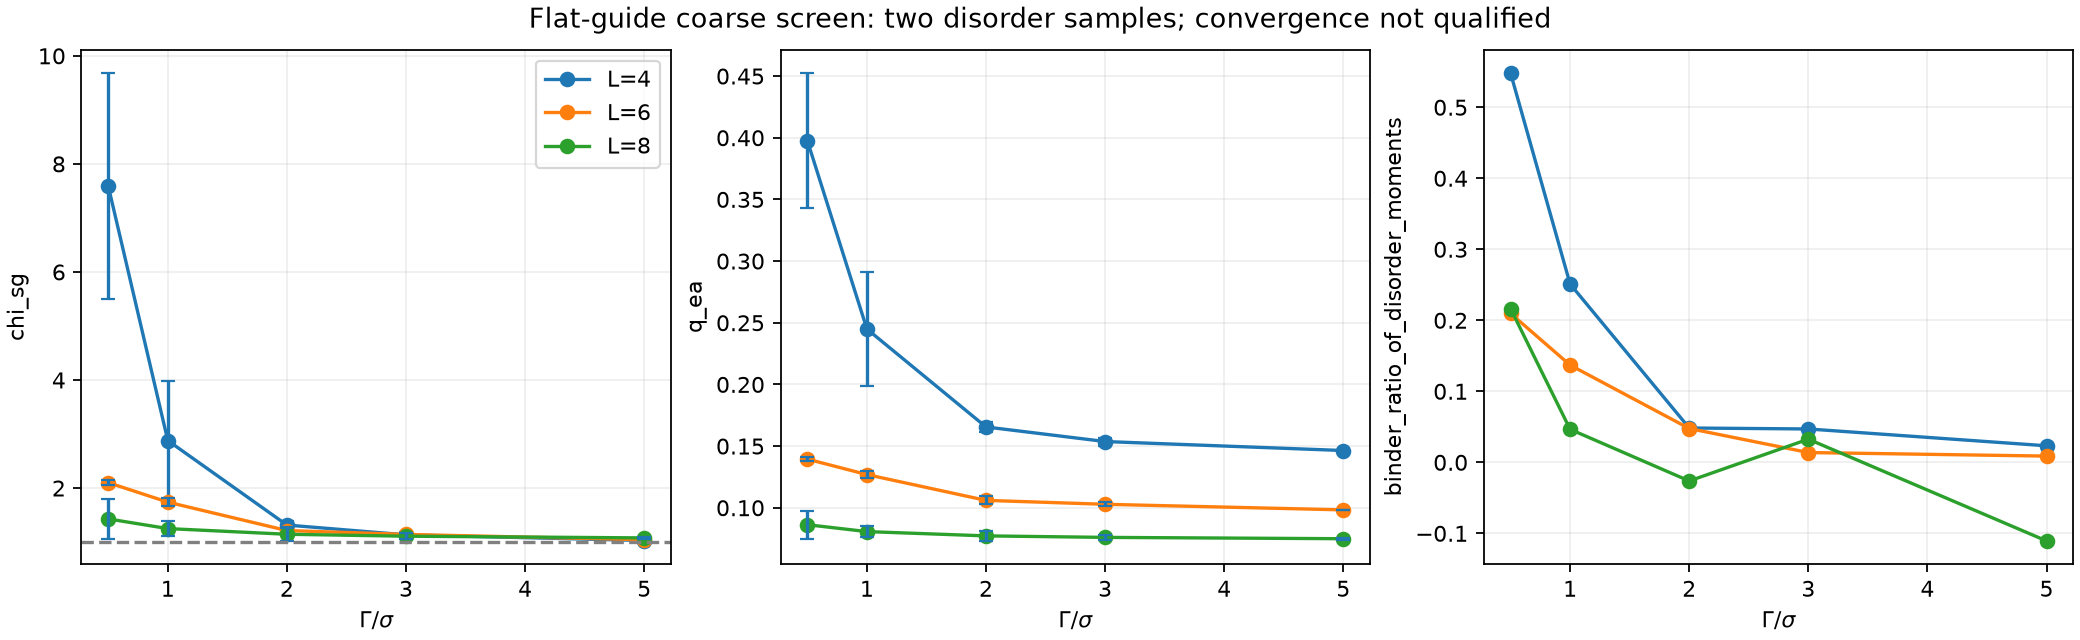

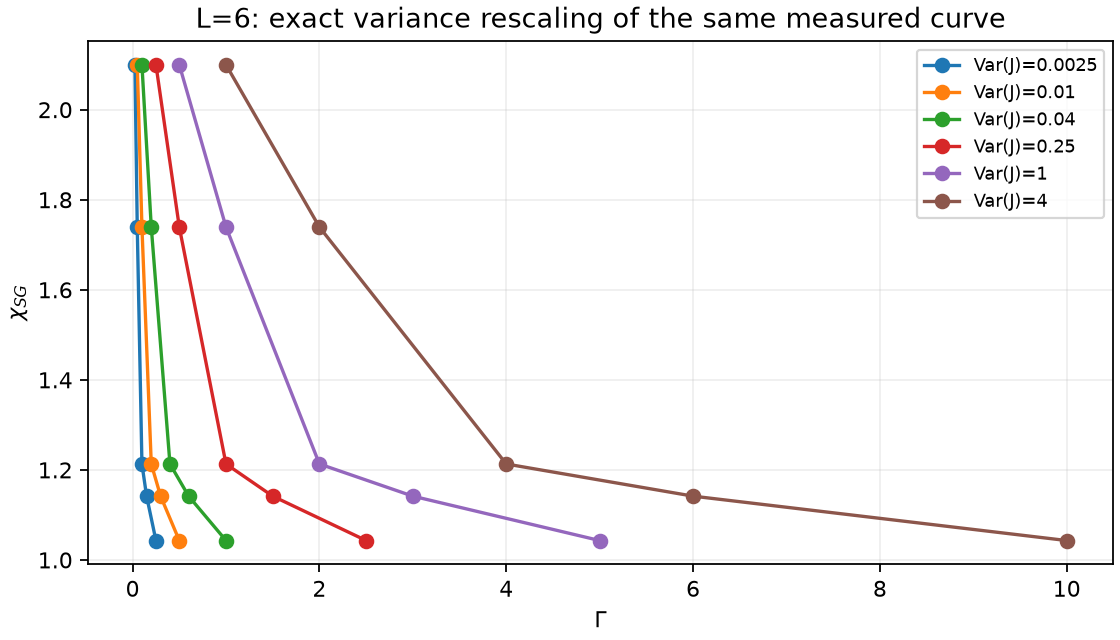

Exploratory disorder screen: convergence qualification and a transition estimate require review of these contrasts, lineage diagnostics and more disorder samples.

In [14]:
scan_dir = campaign_dir.parent/'gaussian-size-field-20261026'
scan_campaign = json.loads((scan_dir/'campaign.json').read_text())
assert len(scan_campaign['tasks']) == 192
assert scan_campaign['source_sha256'] == overlap_campaign['source_sha256']
for name, digest in scan_campaign['study_sha256'].items():
    assert hashlib.sha256((scan_dir/name).read_bytes()).hexdigest() == digest, name
scan_harness = (scan_dir/'scan.py').read_text()
scan_node = next(n for n in ast.parse(scan_harness).body if isinstance(n, ast.FunctionDef) and n.name == 'project')
display(Markdown('```python\n'+ast.get_source_segment(scan_harness, scan_node)+'\n```'))
if (scan_dir/'final.json').exists() and (scan_dir/'exit.json').exists():
    import subprocess
    verification = subprocess.run([sys.executable, str(scan_dir/'verify.py')], check=True, capture_output=True, text=True)
    print(verification.stdout)
    scan_saved = json.loads((scan_dir/'final.json').read_text())
    table = ['| L | Gamma/sigma | chi SG | q EA | Binder | Complete forward cycles |', '|---:|---:|---:|---:|---:|---|']
    for row in scan_saved['curves']:
        table.append(f"| {row['L']} | {row['gamma_over_sigma']:g} | {row['chi_sg']:.6f} | {row['q_ea']:.6f} | {row['binder_ratio_of_disorder_moments']:.6f} | {row['all_projection_complete']} |")
    display(Markdown('\n'.join(table)))
    comparisons = ['| Comparison (sample 0) | chi SG difference | 95% CI | Energy/spin difference | 95% CI |', '|---|---:|---|---:|---|']
    for name, record in scan_saved['convergence_contrasts'].items():
        c, e = record['chi_sg'], record['energy_per_spin']
        comparisons.append(f"| {name} | {c['mean']:.6f} | {c['ci95']} | {e['mean']:.6f} | {e['ci95']} |")
    display(Markdown('\n'.join(comparisons)))
    from IPython.display import Image
    subprocess.run([sys.executable, str(scan_dir/'render_latex_plots.py')], check=True)
    display(Image(filename=str(scan_dir/'size_field_screen_latex.png')))
    display(Image(filename=str(scan_dir/'variance_rescaling_latex.png')))
    display(Markdown('Exploratory disorder screen: convergence qualification and a transition estimate require review of these contrasts, lineage diagnostics and more disorder samples.'))
else:
    for status_name in ('launch.json', 'progress.json', 'exit.json'):
        if (scan_dir/status_name).exists():
            print(status_name, (scan_dir/status_name).read_text())
    print('Full local size/field results are pending. No transition estimate is available yet.')